# ` Intelligent E-Commerce Customer Analytics Platform `

# Step 1: Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

# Step 2: Load the Integrated Dataset

In [2]:
df = pd.read_csv("../data/processed/customer_analytics_dataset.csv")

print(df.shape)
print()
print(df.info())
print()
print(df.head())

(119143, 40)

<class 'pandas.DataFrame'>
RangeIndex: 119143 entries, 0 to 119142
Data columns (total 40 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   customer_id                    119143 non-null  str    
 1   customer_unique_id             119143 non-null  str    
 2   customer_zip_code_prefix       119143 non-null  int64  
 3   customer_city                  119143 non-null  str    
 4   customer_state                 119143 non-null  str    
 5   order_id                       119143 non-null  str    
 6   order_status                   119143 non-null  str    
 7   order_purchase_timestamp       119143 non-null  str    
 8   order_approved_at              118966 non-null  str    
 9   order_delivered_carrier_date   117057 non-null  str    
 10  order_delivered_customer_date  115722 non-null  str    
 11  order_estimated_delivery_date  119143 non-null  str    
 12  order_item_id              

# Step 3: Convert Date Columns

In [3]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
    "shipping_limit_date",
    "review_creation_date",
    "review_answer_timestamp"
]

for col in date_columns:
    df[col] = pd.to_datetime(df[col], errors="coerce")

# Step 4: Missing Values

In [4]:
missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": (df.isnull().sum()/len(df))*100
})

missing = missing[missing["Missing Values"]>0]
missing.sort_values("Percentage", ascending=False)

,Missing Values,Percentage
review_comment_title,105154,88.258647
review_comment_message,68898,57.827988
order_delivered_customer_date,3421,2.871339
product_category_name_english,2567,2.154554
product_description_lenght,2542,2.133571
product_category_name,2542,2.133571
product_name_lenght,2542,2.133571
product_photos_qty,2542,2.133571
order_delivered_carrier_date,2086,1.750837
review_score,997,0.836810


# Step 5: Handle Missing Values

In [5]:
# Product Category 
df["product_category_name_english"] = (df["product_category_name_english"].fillna("Unknown"))

#Review Title
df["review_comment_title"] = (df["review_comment_title"].fillna("No Title"))

#Review Comments
df["review_comment_message"] = (df["review_comment_message"].fillna("No Comment"))

# Product Dimensions
numeric_columns = [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm",
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty"
]
for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

# Step 6: Duplicate Records

In [6]:
print("Dupicate Rows:", df.duplicated().sum())

Dupicate Rows: 0


# Step 7: Check Invalid Values

In [7]:
print("Negative prices:", (df["price"] < 0).sum())
print("Negative freight:", (df["freight_value"] < 0).sum())
print("Negative payment:", (df["payment_value"] < 0).sum())

Negative prices: 0
Negative freight: 0
Negative payment: 0


# Step 8: Outlier Detection

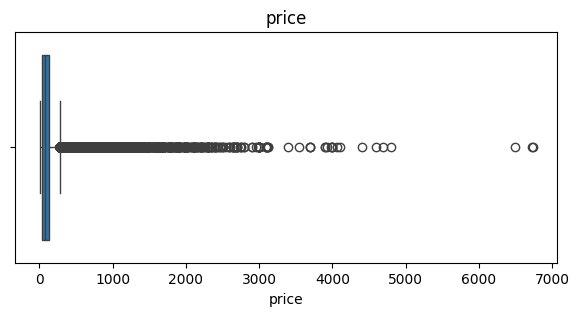

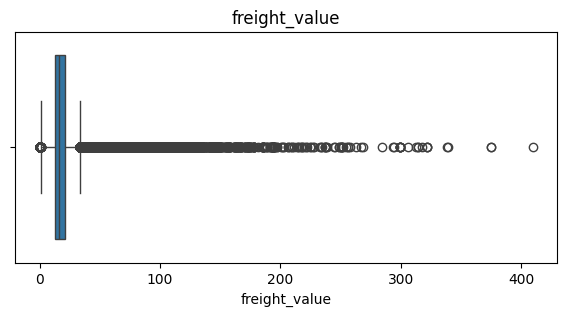

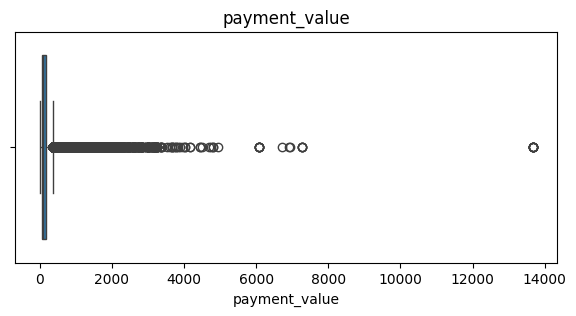

In [8]:
columns = [
    "price",
    "freight_value",
    "payment_value"
]

for col in columns:
    plt.figure(figsize=(7,3))
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

# Step 9: Handle Outliers

In [9]:
def remove_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return data[(data[column] >= lower) &(data[column] <= upper)]

print("Original Shape:", df.shape)
temp_df = df.copy()
for col in ["price", "payment_value", "freight_value"]:
    temp_df = remove_outliers(temp_df, col)
print("Shape After Removing Outliers:", temp_df.shape)
rows_removed = len(df) - len(temp_df)

print(f"Rows Removed: {rows_removed}")
print(f"Percentage Removed: {(rows_removed/len(df))*100:.2f}%")

Original Shape: (119143, 40)
Shape After Removing Outliers: (94695, 40)
Rows Removed: 24448
Percentage Removed: 20.52%


### *Outlier Analysis*

         1. The IQR method identified approximately 20.52% of the records as outliers in the monetary variables (price, payment_value, and freight_value).
         2. These values represent genuine high-value transactions rather than erroneous data. Removing over 20% of the observations would result in significant information loss.
         3. Therefore, no outliers were removed during the data cleaning phase. Instead, the original data was retained.

# Step 10: Merge Geolocation

In [10]:
geolocation = pd.read_csv("../data/raw/olist_geolocation_dataset.csv")
geo = (
    geolocation
    .groupby("geolocation_zip_code_prefix")
    .agg({
        "geolocation_lat": "mean",
        "geolocation_lng": "mean",
        "geolocation_city": "first",
        "geolocation_state": "first"
    })
    .reset_index()
)

df = pd.merge(
    df,
    geo,
    left_on="customer_zip_code_prefix",
    right_on="geolocation_zip_code_prefix",
    how="left"
)
# Now each customer record has approximate latitude and longitude without creating duplicate rows.

# Step 11: Final Check

In [11]:
print(df.shape)
print(df.info())


(119143, 45)
<class 'pandas.DataFrame'>
RangeIndex: 119143 entries, 0 to 119142
Data columns (total 45 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   customer_id                    119143 non-null  str           
 1   customer_unique_id             119143 non-null  str           
 2   customer_zip_code_prefix       119143 non-null  int64         
 3   customer_city                  119143 non-null  str           
 4   customer_state                 119143 non-null  str           
 5   order_id                       119143 non-null  str           
 6   order_status                   119143 non-null  str           
 7   order_purchase_timestamp       119143 non-null  datetime64[us]
 8   order_approved_at              118966 non-null  datetime64[us]
 9   order_delivered_carrier_date   117057 non-null  datetime64[us]
 10  order_delivered_customer_date  115722 non-null  datetime64[us]
 11

# Step 12: Save the Clean Dataset

In [12]:
df.to_csv("../data/processed/customer_analytics_cleaned.csv",index=False)
print("Clean Dataset Saved Successfully!")

Clean Dataset Saved Successfully!


In [31]:
from dashboard.utils.data_loader import load_customer_segments

segments = load_customer_segments()

print("Shape:", segments.shape)

print(
    segments.columns.tolist()
)

display(segments.head())

ImportError: cannot import name 'load_customer_segments' from 'dashboard.utils.data_loader' (c:\Users\RAaM\OneDrive\Desktop\E-Commerce Customer Analytics\dashboard\utils\data_loader.py)